# Windkessel: a first differential-equation experiment

Read [the model chapter](../docs/models/Windkessel.md) and [source map](../docs/SOURCE_MAP.md).
Sources: [Wang et al. (2003)](https://doi.org/10.1152/ajpheart.00175.2002),
p. H1359, equations (1)–(3); [Alastruey (2010)](https://doi.org/10.1007/s10558-010-9109-9),
equations (1)–(2). We take zero inflow and constant resistance, compliance,
and reference pressure. The implementation is one restricted component, not a heartbeat simulator.

$$0=C\,p'(t)+\frac{p(t)-p_{out}}{R},\qquad
p(t)=p_{out}+(p_{init}-p_{out})e^{-t/(RC)}.$$

**All values are synthetic**, chosen for easy arithmetic. No patient data,
parameter fit, or physiological accuracy is claimed. Python floats and numerical
integration do not replace the exact real-number proofs in
[Windkessel.lean](../CardioLean/Circulation/Windkessel.lean).

## 1. Check an exact curve

R is in mmHg·s/mL; C is in mL/mmHg; time is in s; pressure is in mmHg.
The chosen reference is 5 mmHg, not an assumed measured venous pressure.
The time constant is RC = 1 s. At that time the pressure **difference** above
the reference is multiplied by exp(-1), not the absolute pressure.

In [1]:
import math
from pathlib import Path
import matplotlib.pyplot as plt

R = 2.0
C = 0.5
p_out = 5.0
p_init = 15.0
tau = R * C
assert R > 0 and C > 0 and p_init >= p_out


def pressure(t, resistance=R, compliance=C):
    if resistance <= 0 or compliance <= 0 or t < 0:
        raise ValueError("Use positive R, C and nonnegative elapsed time.")
    return p_out + (p_init - p_out) * math.exp(-t / (resistance * compliance))


times = [i * tau / 100 for i in range(501)]
values = [pressure(t) for t in times]
assert values[0] == p_init
assert all(p_out <= p <= p_init for p in values)
assert all(b <= a for a, b in zip(values, values[1:]))
assert math.isclose((pressure(tau) - p_out) / (p_init - p_out), math.exp(-1))
print(f"RC = {tau:g} s; p(RC) = {pressure(tau):.6f} mmHg")
print("501 finite samples satisfy the expected bounds and ordering.")

RC = 1 s; p(RC) = 8.678794 mmHg
501 finite samples satisfy the expected bounds and ordering.


## 2. Test a numerical approximation

Forward Euler estimates the next pressure as `p_next = p + dt * p_rate`.
Here `p_rate = -(p-p_out)/(R*C)`. It is a project experiment; this numerical
scheme has not been formalized in Lean. Compare successively smaller time
steps against the closed form. A large time step can cross below the reference
pressure, violating a bound that the exact solution satisfies.

In [2]:
def euler(dt, steps):
    points = [(0.0, p_init)]
    p = p_init
    for i in range(steps):
        p += dt * (-(p - p_out) / tau)
        points.append(((i + 1) * dt, p))
    return points


errors = []
for steps in (4, 8, 16, 32):
    dt = tau / steps
    approximate = euler(dt, steps)[-1][1]
    error = abs(approximate - pressure(tau))
    errors.append(error)
    print(f"dt={dt:.5f} s; absolute error at RC={error:.6f} mmHg")
assert all(b < a for a, b in zip(errors, errors[1:]))
large_step = euler(1.25 * tau, 4)
assert large_step[1][1] < p_out
print("Large-step first pressure:", large_step[1][1], "mmHg; below the 5 mmHg reference.")

dt=0.25000 s; absolute error at RC=0.514732 mmHg
dt=0.12500 s; absolute error at RC=0.242705 mmHg
dt=0.06250 s; absolute error at RC=0.118053 mmHg
dt=0.03125 s; absolute error at RC=0.058242 mmHg
Large-step first pressure: 2.5 mmHg; below the 5 mmHg reference.


## 3. Test what pressure alone can identify

Doubling R and halving C leaves RC unchanged, so this particular pressure curve
is unchanged. The Lean theorem `decay_eq_of_product_eq` proves that statement
for all real times. It is a restriction of this zero-inflow experiment: it does
not say R and C are indistinguishable under all measurements or forced-flow models.
The outflows for these two choices can differ, giving a reason to seek additional data.

In [3]:
other_R, other_C = 4.0, 0.25
other_values = [pressure(t, other_R, other_C) for t in times]
assert all(math.isclose(a, b) for a, b in zip(values, other_values))
initial_outflow = (p_init - p_out) / R
other_outflow = (p_init - p_out) / other_R
assert not math.isclose(initial_outflow, other_outflow)
print(f"Same pressure curve; initial outflows {initial_outflow:g} and {other_outflow:g} mL/s.")

Same pressure curve; initial outflows 5 and 2.5 mL/s.


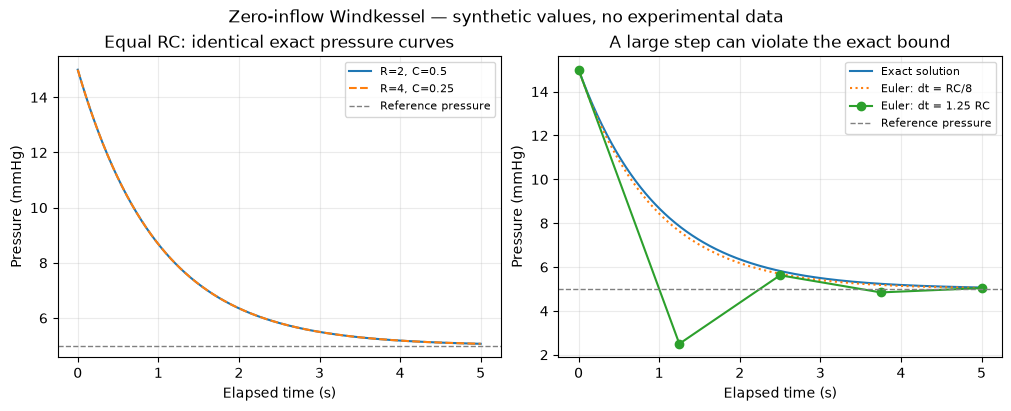

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
for resistance, compliance in ((R, C), (other_R, other_C)):
    axes[0].plot(times, [pressure(t, resistance, compliance) for t in times],
                 linestyle="-" if resistance == R else "--",
                 label=f"R={resistance:g}, C={compliance:g}")
axes[0].set_title("Equal RC: identical exact pressure curves")
axes[1].plot(times, values, label="Exact solution")
fine = euler(tau / 8, 40)
axes[1].plot(*zip(*fine), linestyle=":", label="Euler: dt = RC/8")
axes[1].plot(*zip(*large_step), marker="o", label="Euler: dt = 1.25 RC")
axes[1].set_title("A large step can violate the exact bound")
for ax in axes:
    ax.axhline(p_out, color="gray", linestyle="--", linewidth=1, label="Reference pressure")
    ax.set_xlabel("Elapsed time (s)")
    ax.set_ylabel("Pressure (mmHg)")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
fig.suptitle("Zero-inflow Windkessel — synthetic values, no experimental data")
repo_root = Path.cwd() if Path("CardioLean.lean").exists() else Path.cwd().parent
assert (repo_root / "CardioLean.lean").is_file()
output = repo_root / "docs/assets/windkessel-exploration.png"
output.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(output, dpi=160, metadata={"Software": "CardioLean Windkessel notebook"})
plt.show()

## What remains to learn or implement

- What does differentiability mean, and why is checking the initial value insufficient?
- Why does `SatisfiesBalanceAt` include a derivative witness as well as an equation?
- Which theorem assumptions fail if C is zero or negative? See `test/ModelChecks.lean`.
- How would a nonzero inflow change the solution and the information available for fitting?
- How should a valve, chamber volume, and ventricular pressure be connected without creating or losing volume?

The notebook checks finite numerical cases. Lean checks the explicit solution,
its derivative, flow balance, bounds, nonincrease, time-constant identity, and
same-RC equality. General-input existence, uniqueness, numerical-method guarantees,
parameter fitting, and coupling to Hill contraction remain open work.